# RT-DETR evaluation on African Wildlife

Train and evaluate a single Ultralytics RT-DETR object-detection model on african-wildlife dataset. Ultralytics provides pretrained weights for `rtdetr-l.pt` and `rtdetr-x.pt`; this notebook defaults to RT-DETR-L.


In [8]:
# Install dependencies
%pip install -q -U ultralytics pandas matplotlib


In [9]:
from pathlib import Path
import time

import pandas as pd
import torch
from IPython.display import display
from ultralytics import RTDETR

DATA = "african-wildlife.yaml"
MODEL_NAME = "RT-DETR-L"
WEIGHTS = "rtdetr-l.pt"  # Use rtdetr-x.pt for the larger model

EPOCHS = 100
IMGSZ = 640
BATCH = 16
SEED = 42
DEVICE = 0 if torch.cuda.is_available() else "cpu"

RUN_DIR = Path("runs/african_wildlife")
RUN_DIR.mkdir(parents=True, exist_ok=True)
print(f"Using device: {DEVICE}")


Using device: 0


In [10]:
# Train RT-DETR
start_time = time.time()

model = RTDETR(WEIGHTS)
model.train(
    data=DATA,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    seed=SEED,
    project=str(RUN_DIR),
    name="rtdetr",
    exist_ok=True,
    pretrained=True,
    plots=True,
)

training_time_min = (time.time() - start_time) / 60
weights_path = Path(model.trainer.save_dir) / "weights" / "best.pt"
print(f"Best weights: {weights_path}")
print(f"Training time: {training_time_min:.2f} minutes")


Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr, nbs=64, nms=False, opset=None, 

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      13.7G      0.364       2.64     0.3578         37        640: 100% ━━━━━━━━━━━━ 66/66 1.1s/it 1:13
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.4s/it 11.0s
                   all        225        379      0.815      0.747      0.834      0.679

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      2/100      13.7G     0.3033      0.608     0.3102         53        640: 100% ━━━━━━━━━━━━ 66/66 1.1s/it 1:11
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.7it/s 4.8s
                   all        225        379      0.767       0.64      0.713       0.54

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


...

     98/100      13.7G    0.06647     0.1349    0.07156         21        640: 100% ━━━━━━━━━━━━ 66/66 1.1s/it 1:10
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.7it/s 4.7s
                   all        225        379       0.95      0.917       0.95      0.836

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     99/100      13.7G    0.06585     0.1368    0.07104         27        640: 100% ━━━━━━━━━━━━ 66/66 1.1s/it 1:09
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.7it/s 4.7s
                   all        225        379       0.95      0.911      0.945      0.832

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
    100/100      13.7G    0.05813      0.122    0.06839         20        640: 0% ──────────── 0/66  1.0s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


    100/100      13.7G    0.06551     0.1362    0.06786         22        640: 100% ━━━━━━━━━━━━ 66/66 1.1s/it 1:09
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.7it/s 4.8s
                   all        225        379      0.936      0.922      0.946      0.835

100 epochs completed in 2.643 hours.
Optimizer stripped from /content/runs/detect/runs/african_wildlife/rtdetr/weights/last.pt, 66.2MB
Optimizer stripped from /content/runs/detect/runs/african_wildlife/rtdetr/weights/best.pt, 66.2MB

Validating /content/runs/detect/runs/african_wildlife/rtdetr/weights/best.pt...
Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary: 315 layers, 31,991,960 parameters, 0 gradients, 105.3 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.1it/s 7.0s
                   all        225        379      0.952      0.908

In [11]:
# Evaluate RT-DETR on the test split
evaluation_model = RTDETR(str(weights_path))
metrics = evaluation_model.val(
    data=DATA,
    split="test",
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    plots=True,
)

results = {
    "Model": MODEL_NAME,
    "Precision": metrics.box.mp,
    "Recall": metrics.box.mr,
    "mAP50": metrics.box.map50,
    "mAP50-95": metrics.box.map,
    "mAP75": metrics.box.map75,
    "Training time (min)": training_time_min,
    "Best weights": str(weights_path),
}

evaluation_df = pd.DataFrame([results])
display(evaluation_df.style.format({
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "mAP50": "{:.4f}",
    "mAP50-95": "{:.4f}",
    "mAP75": "{:.4f}",
    "Training time (min)": "{:.2f}",
}))


Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary: 315 layers, 31,991,960 parameters, 0 gradients, 105.3 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 29.7±23.5 MB/s, size: 141.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/datasets/african-wildlife/labels/test... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 541.1it/s 0.4s
val: New cache created: /content/datasets/african-wildlife/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 1.1it/s 14.1s
                   all        227        375      0.982      0.907      0.955      0.854
               buffalo         49         66      0.989      0.909      0.953      0.883
              elephant         58         99      0.977      0.865      0

,Model,Precision,Recall,mAP50,mAP50-95,mAP75,Training time (min),Best weights
0,RT-DETR-L,0.9820,0.9070,0.9551,0.8540,0.9210,159.08,/content/runs/detect/runs/african_wildlife/rtdetr/weights/best.pt


In [12]:
# Save RT-DETR evaluation results
evaluation_df.to_csv(RUN_DIR / "rtdetr_evaluation.csv", index=False)
evaluation_df.to_json(RUN_DIR / "rtdetr_evaluation.json", orient="records", indent=2)
print(f"Saved results to: {RUN_DIR / 'rtdetr_evaluation.csv'}")
print(f"Saved results to: {RUN_DIR / 'rtdetr_evaluation.json'}")


Saved results to: runs/african_wildlife/rtdetr_evaluation.csv
Saved results to: runs/african_wildlife/rtdetr_evaluation.json


### Download Results

After running the evaluation, you might want to download the generated files (e.g., the evaluation CSV and JSON, and any plots or training logs) to your local machine for further analysis or reporting. The following cell provides a simple way to do this using `google.colab.files`.

In [13]:
from google.colab import files

# Download the evaluation CSV
csv_path = RUN_DIR / "rtdetr_evaluation.csv"
if csv_path.exists():
    files.download(csv_path)
    print(f"Downloaded {csv_path}")
else:
    print(f"File not found: {csv_path}")

# Download the evaluation JSON
json_path = RUN_DIR / "rtdetr_evaluation.json"
if json_path.exists():
    files.download(json_path)
    print(f"Downloaded {json_path}")
else:
    print(f"File not found: {json_path}")

# You can add more files to download here, for example:
# For training plots, you might download the `results.png` or `confusion_matrix.png`
# from the model's training directory (model.trainer.save_dir).
# For example:
# plots_path = Path(model.trainer.save_dir) / "results.png"
# if plots_path.exists():
#     files.download(plots_path)
#     print(f"Downloaded {plots_path}")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded runs/african_wildlife/rtdetr_evaluation.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded runs/african_wildlife/rtdetr_evaluation.json


In [14]:
# Metric guide
metric_guide = pd.DataFrame([
    ["Precision", "Correct predictions / all predictions", "Higher is better when false alarms matter."],
    ["Recall", "Correct detections / all real objects", "Higher is better when missed animals matter."],
    ["mAP50", "Average detection accuracy at IoU 0.50", "Broad detection quality; higher is better."],
    ["mAP50-95", "Average mAP from IoU 0.50 to 0.95", "Primary overall metric; rewards accurate, tight boxes."],
    ["mAP75", "Average detection accuracy at IoU 0.75", "Stricter box-localization quality; higher is better."],
    ["Training time", "Minutes required to train", "Useful for planning and repeatability."],
], columns=["Metric", "What the metric is", "What it tells us"])

display(metric_guide)
print("Evaluation rule: use test mAP50-95 as the primary accuracy metric. For wildlife monitoring, also inspect recall because missed animals may be costly.")


,Metric,What the metric is,What it tells us
0,Precision,Correct predictions / all predictions,Higher is better when false alarms matter.
1,Recall,Correct detections / all real objects,Higher is better when missed animals matter.
2,mAP50,Average detection accuracy at IoU 0.50,Broad detection quality; higher is better.
3,mAP50-95,Average mAP from IoU 0.50 to 0.95,"Primary overall metric; rewards accurate, tigh..."
4,mAP75,Average detection accuracy at IoU 0.75,Stricter box-localization quality; higher is b...
5,Training time,Minutes required to train,Useful for planning and repeatability.


Evaluation rule: use test mAP50-95 as the primary accuracy metric. For wildlife monitoring, also inspect recall because missed animals may be costly.


In [15]:
# Print the evaluated model and key results
row = evaluation_df.iloc[0]
print(f"Model: {row['Model']}")
print(f"Weights: {row['Best weights']}")
print(f"Test mAP50-95: {row['mAP50-95']:.4f}")
print(f"Test Recall: {row['Recall']:.4f}")


Model: RT-DETR-L
Weights: /content/runs/detect/runs/african_wildlife/rtdetr/weights/best.pt
Test mAP50-95: 0.8540
Test Recall: 0.9070


<Axes: title={'center': 'African Wildlife Test-Set RT-DETR Evaluation'}, xlabel='Model'>

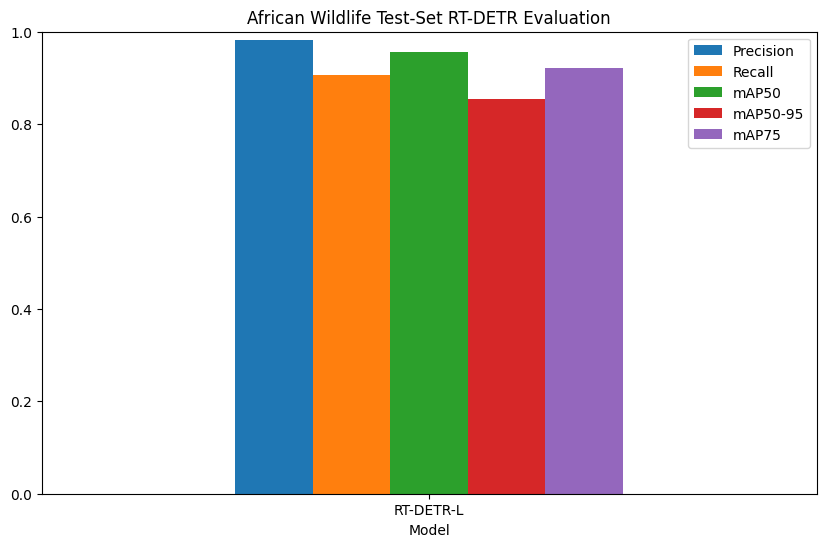

In [16]:
# Plot the RT-DETR metrics
evaluation_df.set_index("Model")[["Precision", "Recall", "mAP50", "mAP50-95", "mAP75"]].plot(
    kind="bar", figsize=(10, 6), ylim=(0, 1), rot=0,
    title="African Wildlife Test-Set RT-DETR Evaluation"
)
